In [6]:

import sys

import os
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns 
import torch
import wandb

sys.path.append(os.path.abspath("../src"))


In [7]:
from deeplearning.training import run_baseline, RunConfig, FitConfig
from deeplearning.wandb_tools import WandbRuns
from deeplearning.model import BaselineCNN

# General Configurations
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42

In [8]:
# Wandb Configurations
wandb_runs = WandbRuns(project="DEL", entity="lukas-breiter-fachhochschule-nordwestschweiz-fhnw")
project_path = (f"{wandb_runs.entity}/{wandb_runs.project}")
api = wandb.Api()

In [9]:
runtime_group_specs = [
    ("Baseline", {"config.experiment_name": "Baseline_HypTests", "config.is_summary_run": False}),
    ("Hypothesis 01", {"config.experiment_name": "Hypothese_01", "config.is_summary_run": False}),
    ("Hypothesis 02", {"config.experiment_name": "Hypothese_02", "config.is_summary_run": False}),
    ("Hypothesis 03", {"config.experiment_name": "Hypothese_03", "config.is_summary_run": False}),
    ("Hypothesis 04", {"config.experiment_name": "Hypothese_04", "config.is_summary_run": False}),
    ("Hypothesis 05", {"config.experiment_name": "Hypothese_05", "config.is_summary_run": False}),
    ("Hypothesis 06", {"config.experiment_name": "Hypothese_06", "config.is_summary_run": False}),
    ("Hypothesis 07", {"config.experiment_name": "Hypothese_07", "config.is_summary_run": False}),
    ("Hypothesis 08", {"config.experiment_name": "Hypothese_08", "config.is_summary_run": False}),
    ("Hypothesis 09", {"config.experiment_name": "Hypothese_09", "config.is_summary_run": False}),
    ("Hypothesis 10", {"config.experiment_name": "Hypothese_10", "config.is_summary_run": False}),
    ("Best model", {"config.experiment_name": "Best_Modell", "config.is_summary_run": False}),
]


In [10]:
runtime_rows = []
for group_name, filters in runtime_group_specs:
    runs = list(api.runs(path=project_path, filters=filters, order="-created_at"))
    for run in runs:
        runtime_seconds = run.summary.get("_runtime")
        if runtime_seconds is None:
            continue
        runtime_rows.append(
            {
                "group": group_name,
                "run_id": run.id,
                "run_name": run.name,
                "runtime_minutes": float(runtime_seconds) / 60.0,
            }
        )


In [11]:

runtime_df = pd.DataFrame(runtime_rows)
group_order = [name for name, _ in runtime_group_specs]
order_lookup = {name: index for index, name in enumerate(group_order)}
summary_df = (
    runtime_df.groupby("group", as_index=False)
    .agg(
        run_count=("run_id", "count"),
        median_runtime_minutes=("runtime_minutes", "median"),
        mean_runtime_minutes=("runtime_minutes", "mean"),
    )
    .sort_values("group", key=lambda series: series.map(order_lookup))
)

display(summary_df)


,group,run_count,median_runtime_minutes,mean_runtime_minutes
0,Baseline,15,1.054471,1.056684
2,Hypothesis 01,15,1.245932,1.247929
3,Hypothesis 02,15,2.391868,2.392138
4,Hypothesis 03,15,0.681965,0.681489
5,Hypothesis 04,15,2.554377,2.557495
6,Hypothesis 05,15,0.981731,0.981225
7,Hypothesis 06,15,1.451080,1.455372
8,Hypothesis 07,15,1.081307,1.081183
9,Hypothesis 08,30,0.976927,0.976984
10,Hypothesis 09,15,1.045869,1.046415


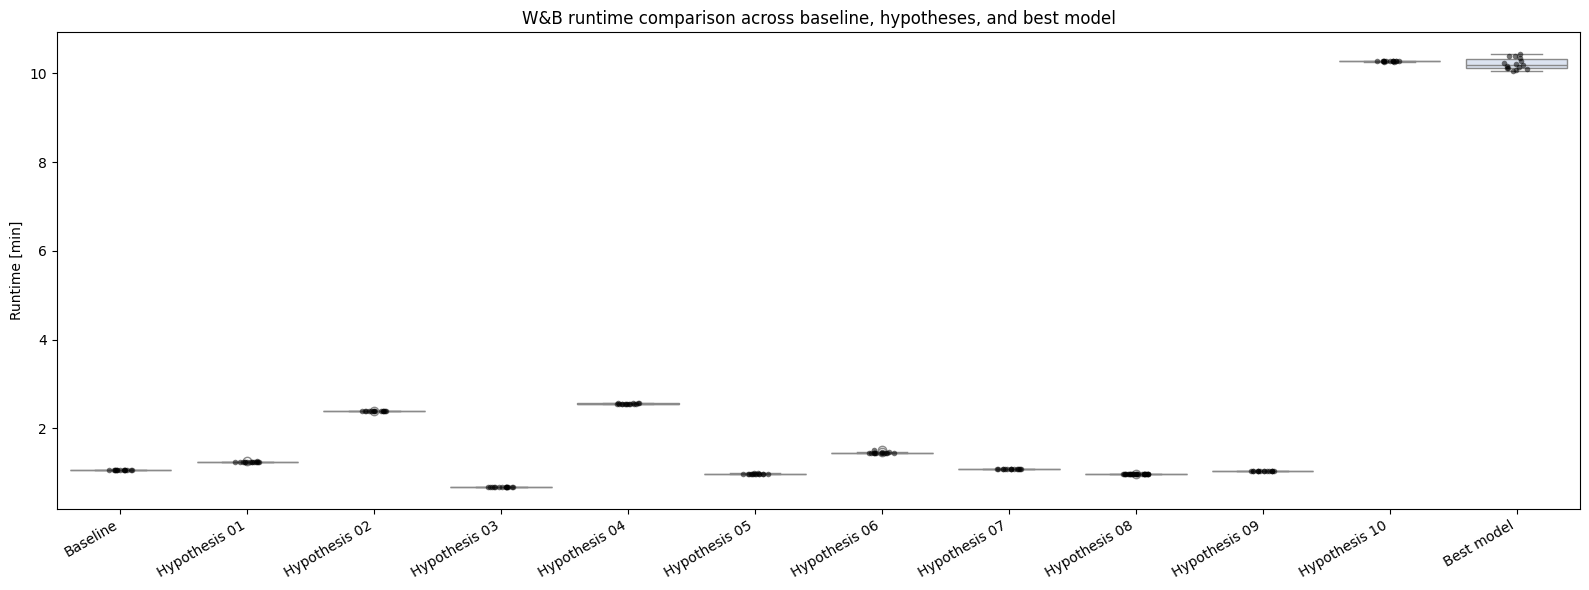

In [12]:

plt.figure(figsize=(16, 6))
sns.boxplot(
    data=runtime_df,
    x="group",
    y="runtime_minutes",
    order=group_order,
    color="#d9e2f3",
)
sns.stripplot(
    data=runtime_df,
    x="group",
    y="runtime_minutes",
    order=group_order,
    color="black",
    alpha=0.55,
    size=4,
)
plt.title("W&B runtime comparison across baseline, hypotheses, and best model")
plt.xlabel("")
plt.ylabel("Runtime [min]")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()